# Seller Segmentation theo đề xuất leader
**Tzy — bước 1 đến 3, cập nhật 27/11/2026.**

Tính toàn bộ đặc trưng đề xuất ở cấp seller, chọn bộ 12–15 cột bằng dữ liệu thật, xuất cùng ma trận cho K-Means/GMM/DBSCAN.
Nguồn CSV thô hoặc SQLite giữ nguyên lịch sử đơn; tỷ lệ hủy dùng cả đơn chưa giao có item xác định seller.
Notebook chứa đầy đủ mã, không yêu cầu import file trong repo. `SOURCE` phải chứa đủ chín bảng nguồn.


## Bước 1 Chuẩn bị dữ liệu và bảo vệ mức chi tiết
Kiểm tra khóa và quan hệ, gom review trước nối. Chỉ đơn delivered có ngày mua hợp lệ tạo cohort bán hàng.
Geolocation gom median theo zip, fallback city/state; không nhân dòng item. Các chỉ số review, giao hàng, thanh toán được tính từ seller-order.


In [1]:
"""Prepare Olist seller segmentation inputs (steps 1-3, without fitting clusters)."""

from __future__ import annotations

import argparse
import hashlib
import json
import platform
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.preprocessing import StandardScaler


REQUIRED = {
    "sellers": ["seller_id", "seller_city", "seller_state"],
    "order_items": ["order_id", "order_item_id", "seller_id", "product_id", "price", "freight_value"],
    "orders": ["order_id", "order_status", "order_purchase_timestamp",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "products": ["product_id", "product_category_name"],
    "order_reviews": ["order_id", "review_score"],
}
KEYS = {"sellers": ["seller_id"], "orders": ["order_id"],
        "products": ["product_id"], "order_items": ["order_id", "order_item_id"]}
MODEL_FEATURES = [
    "order_count", "avg_order_value", "category_count", "freight_to_price_ratio",
    "review_score_mean", "late_delivery_rate", "delivery_days_mean", "recency_days", "tenure_days",
]
LOG_FEATURES = ["order_count", "avg_order_value", "category_count", "freight_to_price_ratio",
                "delivery_days_mean", "recency_days", "tenure_days"]


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_sources(source):
    """Read the chosen Kaggle SQLite database or its equivalent raw CSV tables."""
    source = Path(source)
    tables, manifest = {}, {}
    if source.is_file():
        if source.suffix.lower() not in {".sqlite", ".sqlite3", ".db"}:
            raise ValueError("Source file must be a SQLite database.")
        with closing(sqlite3.connect(source.resolve().as_uri() + "?mode=ro", uri=True)) as connection:
            available = {row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            for name in REQUIRED:
                if name not in available:
                    raise ValueError(f"Missing SQLite table: {name}")
                tables[name] = pd.read_sql_query(f'SELECT * FROM "{name}"', connection)
        manifest["sqlite"] = {"name": source.name, "sha256": file_sha256(source)}
    elif source.is_dir():
        for name in REQUIRED:
            candidates = [source / f"{name}.csv", source / f"olist_{name}_dataset.csv"]
            existing = [path for path in candidates if path.is_file()]
            if len(existing) != 1:
                raise ValueError(f"Expected one raw CSV for {name}, found {len(existing)} in {source}")
            path = existing[0]
            tables[name] = pd.read_csv(path, dtype={column: "string" for column in REQUIRED[name]
                                                  if column.endswith("_id")})
            manifest[name] = {"name": path.name, "sha256": file_sha256(path)}
    else:
        raise FileNotFoundError(f"Olist source not found: {source}")
    return tables, manifest


def prepare_data(tables):
    """Step 1: validate grain/relationships and retain delivered sale items."""
    tables = {name: frame.copy() for name, frame in tables.items()}
    audit = {"source_rows": {}, "exact_duplicates_removed": {}, "invalid_dates": {}}
    for name, columns in REQUIRED.items():
        frame = tables[name]
        missing = set(columns) - set(frame.columns)
        if missing:
            raise ValueError(f"{name}: missing columns {sorted(missing)}")
        audit["source_rows"][name] = len(frame)
        audit["exact_duplicates_removed"][name] = int(frame.duplicated().sum())
        frame = frame.drop_duplicates().copy()
        for column in frame.columns:
            if column.endswith("_id"):
                frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
        if name in KEYS:
            keys = KEYS[name]
            if frame[keys].isna().any().any() or frame.duplicated(keys).any():
                raise ValueError(f"{name}: null or conflicting duplicate key {keys}")
        tables[name] = frame
    sellers, items, orders, products, reviews = (tables[name] for name in REQUIRED)
    for column in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
        parsed = pd.to_datetime(orders[column], errors="coerce", format="mixed")
        audit["invalid_dates"][column] = int((orders[column].notna() & parsed.isna()).sum())
        orders[column] = parsed
    for column in ["price", "freight_value"]:
        items[column] = pd.to_numeric(items[column], errors="coerce")
        if not np.isfinite(items[column]).all() or (items[column] < 0).any():
            raise ValueError(f"order_items.{column}: missing, nonnumeric, infinite or negative value")
    for column, dimension, key in [("seller_id", sellers, "seller_id"),
                                    ("product_id", products, "product_id"),
                                    ("order_id", orders, "order_id")]:
        invalid = items[column].isna() | ~items[column].isin(dimension[key])
        if invalid.any():
            raise ValueError(f"order_items.{column}: {int(invalid.sum())} unmatched keys")
    if reviews["order_id"].isna().any() or not reviews["order_id"].isin(orders["order_id"]).all():
        raise ValueError("order_reviews: null or unmatched order_id")
    reviews["review_score"] = pd.to_numeric(reviews["review_score"], errors="coerce")
    invalid_score = reviews["review_score"].isna() | ~reviews["review_score"].between(1, 5)
    audit["invalid_review_scores"] = int(invalid_score.sum())
    reviews.loc[invalid_score, "review_score"] = np.nan
    # Collapse reviews BEFORE joining: multiple reviews must not multiply sale items.
    order_reviews = reviews.groupby("order_id", as_index=False).agg(review_score=("review_score", "mean"))
    joined = items.merge(orders[REQUIRED["orders"]], on="order_id", validate="many_to_one")
    audit["item_rows_by_order_status"] = {str(k): int(v) for k, v in joined["order_status"].value_counts(dropna=False).items()}
    delivered = joined["order_status"].eq("delivered")
    valid_purchase = joined["order_purchase_timestamp"].notna()
    audit["delivered_items_missing_purchase_date"] = int((delivered & ~valid_purchase).sum())
    sales = joined.loc[delivered & valid_purchase].copy()
    if sales.empty:
        raise ValueError("No delivered sale items with a valid purchase date.")
    sales = sales.merge(products[REQUIRED["products"]], on="product_id", validate="many_to_one")
    sales = sales.merge(order_reviews, on="order_id", how="left", validate="many_to_one")
    audit["eligible_item_rows"] = len(sales)
    audit["eligible_orders"] = int(sales["order_id"].nunique())
    audit["multi_seller_orders"] = int((sales.groupby("order_id")["seller_id"].nunique() > 1).sum())
    audit["orders_with_multiple_reviews"] = int((reviews.groupby("order_id").size() > 1).sum())
    return sales, sellers, audit


def create_features(sales, sellers):
    """Step 2: aggregate item values and order-level service metrics separately."""
    # One row per seller-order prevents item-heavy orders receiving extra weight.
    seller_orders = sales.groupby(["seller_id", "order_id"], as_index=False).agg(
        order_sales=("price", "sum"), order_freight=("freight_value", "sum"),
        purchase_at=("order_purchase_timestamp", "first"),
        delivered_at=("order_delivered_customer_date", "first"),
        estimated_at=("order_estimated_delivery_date", "first"),
        review_score=("review_score", "first"),
    )
    duration = (seller_orders["delivered_at"] - seller_orders["purchase_at"]).dt.total_seconds() / 86400
    valid_delivery = duration.notna() & duration.ge(0)
    seller_orders["delivery_days"] = duration.where(valid_delivery)
    valid_deadline = (valid_delivery & seller_orders["estimated_at"].notna()
                      & seller_orders["estimated_at"].ge(seller_orders["purchase_at"].dt.normalize()))
    # Estimated delivery is a calendar date: delivery later on that same date is on time.
    seller_orders["late_delivery"] = (
        seller_orders["delivered_at"].dt.normalize() > seller_orders["estimated_at"].dt.normalize()
    ).astype(float).where(valid_deadline)
    reference_date = sales["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
    profiles = seller_orders.groupby("seller_id").agg(
        order_count=("order_id", "nunique"), total_sales=("order_sales", "sum"),
        total_freight=("order_freight", "sum"), avg_order_value=("order_sales", "mean"),
        review_score_mean=("review_score", "mean"), reviewed_order_count=("review_score", "count"),
        late_delivery_rate=("late_delivery", "mean"), delivery_days_mean=("delivery_days", "mean"),
        valid_delivery_order_count=("delivery_days", "count"),
        valid_deadline_order_count=("late_delivery", "count"),
        first_sale_at=("purchase_at", "min"), last_sale_at=("purchase_at", "max"),
    )
    item_profiles = sales.groupby("seller_id").agg(
        item_count=("order_item_id", "size"), product_count=("product_id", "nunique"),
        category_count=("product_category_name", "nunique"),
    )
    profiles = profiles.join(item_profiles)
    profiles["freight_to_price_ratio"] = profiles["total_freight"] / profiles["total_sales"].replace(0, np.nan)
    profiles["recency_days"] = (reference_date - profiles["last_sale_at"].dt.normalize()).dt.days
    profiles["tenure_days"] = (reference_date - profiles["first_sale_at"].dt.normalize()).dt.days
    profiles["review_coverage"] = profiles["reviewed_order_count"] / profiles["order_count"]
    profiles = profiles.reset_index().merge(sellers[REQUIRED["sellers"]], on="seller_id", validate="one_to_one")
    profiles = profiles.sort_values("seller_id").reset_index(drop=True)
    excluded = sellers.loc[~sellers["seller_id"].isin(profiles["seller_id"]), REQUIRED["sellers"]].copy()
    excluded["reason"] = "No delivered sale items with a valid purchase date"
    details = {
        "reference_date": reference_date.isoformat(),
        "purchase_start": sales["order_purchase_timestamp"].min().isoformat(),
        "purchase_end": sales["order_purchase_timestamp"].max().isoformat(),
        "eligible_sellers": len(profiles), "excluded_sellers": len(excluded),
        "invalid_delivery_seller_orders": int((~valid_delivery).sum()),
        "invalid_deadline_seller_orders": int((~valid_deadline).sum()),
    }
    return profiles, excluded.sort_values("seller_id"), details


def preprocess_features(profiles):
    """Step 3: median imputation, log1p for skewed features, then z-score scaling."""
    raw = profiles.set_index("seller_id")[MODEL_FEATURES].astype(float)
    raw = raw.replace([np.inf, -np.inf], np.nan)
    if (raw < 0).any().any():
        raise ValueError("Unexpected negative feature value.")
    medians = raw.median()
    if medians.isna().any():
        raise ValueError(f"Entirely missing features: {medians.index[medians.isna()].tolist()}")
    imputed = raw.fillna(medians)
    transformed = imputed.copy()
    transformed[LOG_FEATURES] = np.log1p(transformed[LOG_FEATURES])
    scaler = StandardScaler()
    matrix = pd.DataFrame(scaler.fit_transform(transformed), index=raw.index, columns=MODEL_FEATURES)
    if not np.isfinite(matrix.to_numpy()).all() or not matrix.index.is_unique:
        raise ValueError("Model input contains nonfinite values or duplicate sellers.")
    q1, q3 = raw.quantile(.25), raw.quantile(.75)
    outliers = (raw.lt(q1 - 1.5 * (q3 - q1)) | raw.gt(q3 + 1.5 * (q3 - q1))).sum()
    metadata = {
        "feature_order": MODEL_FEATURES, "log1p_features": LOG_FEATURES,
        "imputation": "per-feature median before log1p", "medians": medians.to_dict(),
        "scaler": "StandardScaler (population variance, ddof=0)",
        "mean": dict(zip(MODEL_FEATURES, scaler.mean_.tolist())),
        "scale": dict(zip(MODEL_FEATURES, scaler.scale_.tolist())),
        "variance": dict(zip(MODEL_FEATURES, scaler.var_.tolist())),
        "missing_before_imputation": raw.isna().sum().to_dict(),
        "iqr_outlier_counts": outliers.to_dict(),
        "outlier_policy": "Retain all eligible sellers; no clipping or automatic outlier deletion.",
        "constant_features": [name for name, variance in zip(MODEL_FEATURES, scaler.var_) if variance == 0],
        "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                     "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    }
    return matrix, metadata


def export_results(profiles, excluded, matrix, audit, metadata, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    profiles.to_csv(output / "seller_features.csv", index=False, float_format="%.10g")
    excluded.to_csv(output / "excluded_sellers.csv", index=False)
    matrix.to_csv(output / "seller_model_input.csv", index=True, float_format="%.10g")
    profiles[MODEL_FEATURES].describe().T.to_csv(output / "feature_summary.csv", float_format="%.10g")
    for name, value in [("data_quality.json", audit), ("preprocessing.json", metadata)]:
        (output / name).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")


def run(source, output):
    tables, manifest = load_sources(source)
    sales, sellers, audit = prepare_data(tables)
    profiles, excluded, details = create_features(sales, sellers)
    matrix, metadata = preprocess_features(profiles)
    audit.update(details)
    audit["source_manifest"] = manifest
    audit["model_shape"] = list(matrix.shape)
    # Independent controls at item grain, BEFORE seller-order aggregation.
    assert len(profiles) + len(excluded) == len(sellers)
    assert profiles["seller_id"].tolist() == matrix.index.tolist()
    assert profiles["item_count"].sum() == len(sales)
    assert np.isclose(profiles["total_sales"].sum(), sales["price"].sum())
    assert np.isclose(profiles["total_freight"].sum(), sales["freight_value"].sum())
    export_results(profiles, excluded, matrix, audit, metadata, output)
    return profiles, matrix, audit, metadata




In [2]:
"""Leader proposal: audited seller features and shared clustering cohort (Tzy)."""


import argparse
import json
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



SEED = 42
CANDIDATES = [
    'order_count', 'avg_order_value', 'recency_days', 'tenure_days',
    'late_delivery_rate', 'delivery_days_mean', 'cancel_rate',
    'review_score_mean', 'low_star_rate', 'category_count', 'category_hhi',
    'price_index', 'avg_ship_distance_km', 'repeat_customer_rate', 'hot_score',
]
# Prefer interpretable representatives when |Pearson r| >= .75 after log/imputation.
PRIORITY = ['order_count', 'avg_order_value', 'recency_days', 'tenure_days',
            'late_delivery_rate', 'review_score_mean', 'category_count',
            'avg_ship_distance_km', 'repeat_customer_rate', 'cancel_rate',
            'price_index', 'hot_score', 'delivery_days_mean', 'category_hhi', 'low_star_rate']
LOG = ['order_count', 'avg_order_value', 'recency_days', 'tenure_days',
       'delivery_days_mean', 'category_count', 'price_index', 'avg_ship_distance_km']
REGIONS = {**dict.fromkeys(['SP','RJ','MG','ES'], 'Sudeste'),
           **dict.fromkeys(['PR','SC','RS'], 'Sul'),
           **dict.fromkeys(['BA','SE','AL','PE','PB','RN','CE','PI','MA'], 'Nordeste'),
           **dict.fromkeys(['AM','RR','AP','PA','TO','RO','AC'], 'Norte'),
           **dict.fromkeys(['MT','MS','GO','DF'], 'Centro-Oeste')}


def normalize_city(series):
    def norm(value):
        if pd.isna(value):
            return pd.NA
        return ' '.join(''.join(c for c in unicodedata.normalize('NFKD', str(value).lower())
                               if not unicodedata.combining(c)).split())
    return series.map(norm).astype('string')


def load_extended(source):
    tables, manifest = load_sources(source)
    source = Path(source)
    extra = ['customers', 'geolocation', 'order_payments', 'leads_closed']
    if source.is_file():
        import sqlite3
        from contextlib import closing
        with closing(sqlite3.connect(source.resolve().as_uri()+'?mode=ro', uri=True)) as con:
            names = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            for name in extra:
                if name not in names:
                    raise ValueError(f'Missing extended source table: {name}')
                tables[name] = pd.read_sql_query(f'SELECT * FROM "{name}"', con)
    else:
        for name in extra:
            paths = [source/f'{name}.csv', source/f'olist_{name}_dataset.csv']
            found = [p for p in paths if p.exists()]
            if len(found) != 1:
                raise ValueError(f'Expected one CSV for {name}: {found}')
            tables[name] = pd.read_csv(found[0])
            manifest[name] = {'name':found[0].name, 'sha256':file_sha256(found[0])}
    return tables, manifest


def validate_unique(frame, keys, name):
    if frame[keys].isna().any().any() or frame.duplicated(keys).any():
        raise ValueError(f'{name}: null or conflicting duplicate key {keys}')


def geo_lookup(geo):
    """One coordinate per zip, then equal-zip-weight city/state fallback."""
    g = geo.copy()
    g['zip'] = pd.to_numeric(g.geolocation_zip_code_prefix, errors='coerce')
    g['city'] = normalize_city(g.geolocation_city)
    g['state'] = g.geolocation_state.astype('string').str.strip().str.upper()
    g['lat'] = pd.to_numeric(g.geolocation_lat, errors='coerce')
    g['lng'] = pd.to_numeric(g.geolocation_lng, errors='coerce')
    # Brazil bounding box: do not average implausible international coordinates.
    valid = g.lat.between(-34, 6) & g.lng.between(-74, -34)
    bad = int((~valid).sum())
    g.loc[~valid, ['lat','lng']] = np.nan
    z = g.groupby('zip')[['lat','lng']].median()
    cities = g.groupby(['state','city','zip'])[['lat','lng']].median().groupby(['state','city']).median()
    states = g.groupby(['state','zip'])[['lat','lng']].median().groupby('state').median()
    return z, cities, states, bad


def resolve_locations(frame, prefix, lookup):
    z, cities, states, _ = lookup
    r = frame.copy()
    r['city'] = normalize_city(r[f'{prefix}_city'])
    r['state'] = r[f'{prefix}_state'].astype('string').str.strip().str.upper()
    r['zip'] = pd.to_numeric(r[f'{prefix}_zip_code_prefix'], errors='coerce')
    r = r.join(z, on='zip')
    r['coordinate_source'] = np.where(r.lat.notna() & r.lng.notna(), 'zip', 'missing')
    for level, keys, values in [('city',['state','city'],cities), ('state',['state'],states)]:
        fill = r[keys].join(values, on=keys)
        missing = r.lat.isna() | r.lng.isna()
        usable = missing & fill.lat.notna() & fill.lng.notna()
        r.loc[usable,['lat','lng']] = fill.loc[usable,['lat','lng']]
        r.loc[usable,'coordinate_source'] = level
    return r


def haversine(lat1, lng1, lat2, lng2):
    a,b,c,d = [np.radians(pd.to_numeric(x, errors='coerce').astype(float)) for x in [lat1,lng1,lat2,lng2]]
    x = np.sin((c-a)/2)**2 + np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(x,0,1)))


def extend_features(tables, sales, profiles):
    """All order ratios use unique seller-order rows, never joined item counts."""
    t = {k:v.drop_duplicates().copy() for k,v in tables.items()}
    for name, keys in [('customers',['customer_id']),('order_payments',['order_id','payment_sequential']),
                       ('leads_closed',['mql_id'])]:
        validate_unique(t[name],keys,name)
    f = profiles.set_index('seller_id').copy()
    s = sales.copy()
    so = s.drop_duplicates(['seller_id','order_id']).copy()
    all_so = t['order_items'][['seller_id','order_id']].drop_duplicates().merge(
        t['orders'][['order_id','order_status']],on='order_id',validate='many_to_one')
    status = all_so.assign(cancel=lambda x:x.order_status.isin(['canceled','unavailable']),
                           undelivered=lambda x:x.order_status.isin(['shipped','invoiced','processing','approved']))
    f = f.join(status.groupby('seller_id').agg(all_order_count=('order_id','size'),
                                              cancel_rate=('cancel','mean'),undelivered_rate=('undelivered','mean')))
    f['items_per_order'] = f.item_count/f.order_count
    so['month'] = so.order_purchase_timestamp.dt.to_period('M').astype(str)
    f['active_months'] = so.groupby('seller_id').month.nunique()
    f['orders_per_active_month'] = f.order_count/f.active_months
    price = s.groupby('seller_id').price
    f['avg_item_price'] = price.mean()
    f['price_cv'] = price.std(ddof=0)/price.mean().replace(0,np.nan)
    product_rev = s.groupby(['seller_id','product_id']).price.sum()
    f['top_product_share'] = product_rev.groupby(level=0).max()/f.total_sales.replace(0,np.nan)
    for name, mask in [('weekend_sales_share',s.order_purchase_timestamp.dt.dayofweek.ge(5)),
                       ('q4_sales_share',s.order_purchase_timestamp.dt.quarter.eq(4))]:
        f[name] = s.assign(amount=s.price.where(mask,0)).groupby('seller_id').amount.sum()/f.total_sales.replace(0,np.nan)
    # Use twelve fully observed calendar months; exclude final partial August 2018.
    cutoff = s.order_purchase_timestamp.max().to_period('M').start_time
    prev_start, recent_start = cutoff-pd.DateOffset(months=12),cutoff-pd.DateOffset(months=6)
    prev=s.loc[s.order_purchase_timestamp.ge(prev_start)&s.order_purchase_timestamp.lt(recent_start)].groupby('seller_id').price.sum()
    recent=s.loc[s.order_purchase_timestamp.ge(recent_start)&s.order_purchase_timestamp.lt(cutoff)].groupby('seller_id').price.sum()
    f['sales_growth'] = recent.reindex(f.index,fill_value=0)/prev.reindex(f.index,fill_value=0).replace(0,np.nan)-1

    # Missing categories explicitly retained as unknown; weights always sum to one.
    s['category'] = s.product_category_name.astype('string').fillna('__unknown__')
    f['known_category_count'] = f.category_count
    f['category_count'] = s.groupby('seller_id').category.nunique()
    sc=s.groupby(['seller_id','category']).agg(revenue=('price','sum'),mean_price=('price','mean')).reset_index()
    cat=s.groupby('category').agg(revenue=('price','sum'),mean_price=('price','mean'),n_sellers=('seller_id','nunique'))
    sc=sc.join(cat,on='category',rsuffix='_cat').join(f[['total_sales']],on='seller_id')
    sc['weight']=sc.revenue/sc.total_sales.replace(0,np.nan)
    sc['hhi']=sc.weight**2
    sc['entropy']=np.where(sc.weight.gt(0),-sc.weight*np.log(sc.weight.clip(lower=1e-300)),0)
    sc.loc[sc.weight.isna(),'entropy']=np.nan
    sc['hot']=sc.weight*sc.revenue_cat/cat.revenue.sum()
    sc['market']=sc.weight*sc.revenue/sc.revenue_cat.replace(0,np.nan)
    sc['price_index']=sc.weight*sc.mean_price/sc.mean_price_cat.replace(0,np.nan)
    sc['competition']=sc.weight*sc.n_sellers
    sc['top10']=sc.weight*sc.category.isin(cat.revenue.nlargest(10).index)
    for target,col in [('category_hhi','hhi'),('category_entropy','entropy'),('hot_score','hot'),
                       ('market_share_in_cat','market'),('price_index','price_index'),
                       ('competition_exposure','competition'),('pct_rev_top10_cat','top10')]:
        f[target]=sc.groupby('seller_id')[col].sum(min_count=1)
    f['top_category_share']=sc.groupby('seller_id').weight.max()
    f['unknown_category_share']=sc.loc[sc.category.eq('__unknown__')].set_index('seller_id').weight.reindex(f.index,fill_value=0)
    # Same complete months in both years. With this source: January-July 2017/2018.
    latest_year=cutoff.year
    month_limit=cutoff.month-1
    if month_limit==0:
        latest_year-=1;month_limit=12
    cy=s.loc[s.order_purchase_timestamp.dt.month.le(month_limit)].assign(year=lambda x:x.order_purchase_timestamp.dt.year)
    base=cy.loc[cy.year.eq(latest_year-1)].groupby('category').price.sum()
    curr=cy.loc[cy.year.eq(latest_year)].groupby('category').price.sum()
    cat['growth']=curr.reindex(cat.index,fill_value=0)/base.reindex(cat.index,fill_value=0).replace(0,np.nan)-1
    sc['cat_growth']=sc.category.map(cat.growth)
    sc['growth_weight']=sc.weight.where(sc.cat_growth.notna(),0)
    sc['growth_contribution']=sc.weight*sc.cat_growth
    gw=sc.groupby('seller_id').growth_weight.sum()
    f['growth_exposure']=sc.groupby('seller_id').growth_contribution.sum(min_count=1)/gw.replace(0,np.nan)
    f['growth_exposure_coverage']=gw
    order_cat=s[['seller_id','order_id','category','review_score']].drop_duplicates()
    cat_review=order_cat.drop_duplicates(['order_id','category']).groupby('category').review_score.mean()
    seller_cat_review=order_cat.groupby(['seller_id','category']).review_score.mean()
    sc=sc.join(seller_cat_review.rename('seller_cat_review'),on=['seller_id','category'])
    sc['review_ratio']=sc.seller_cat_review/sc.category.map(cat_review)
    sc['review_w']=sc.weight.where(sc.review_ratio.notna(),0)
    sc['review_weighted']=sc.weight*sc.review_ratio
    f['review_index']=sc.groupby('seller_id').review_weighted.sum(min_count=1)/sc.groupby('seller_id').review_w.sum().replace(0,np.nan)

    days=(so.order_delivered_customer_date-so.order_purchase_timestamp).dt.total_seconds()/86400
    so['duration']=days.where(days.ge(0))
    promise=(so.order_estimated_delivery_date.dt.normalize()-so.order_purchase_timestamp.dt.normalize()).dt.days
    so['promised']=promise.where(promise.ge(0))
    delta=(so.order_delivered_customer_date.dt.normalize()-so.order_estimated_delivery_date.dt.normalize()).dt.days
    delta=delta.where(so.duration.notna()&so.promised.notna())
    so['late_days']=delta.where(delta.gt(0))
    so['early_days']=(-delta).where(delta.lt(0))
    for target,col,method in [('delivery_days_std','duration','std'),('promised_days_mean','promised','mean'),
                              ('days_late_mean','late_days','mean'),('days_early_mean','early_days','mean')]:
        f[target]=so.groupby('seller_id')[col].agg(method)
    f['freight_per_item']=f.total_freight/f.item_count
    f['review_score_std']=so.groupby('seller_id').review_score.std(ddof=0)
    # Mean of within-order review fractions; each seller-order gets one vote.
    reviews=t['order_reviews'].copy()
    score=pd.to_numeric(reviews.review_score,errors='coerce').where(lambda x:x.between(1,5))
    reviews['five']=score.eq(5).astype(float).where(score.notna())
    reviews['low']=score.le(2).astype(float).where(score.notna())
    reviews['comment']=reviews.review_comment_message.fillna('').str.strip().ne('').astype(float)
    delay=(pd.to_datetime(reviews.review_answer_timestamp,format='mixed',errors='coerce')-
           pd.to_datetime(reviews.review_creation_date,format='mixed',errors='coerce')).dt.total_seconds()/3600
    reviews['answer_hours']=delay.where(delay.ge(0))
    review_order=reviews.groupby('order_id')[['five','low','comment','answer_hours']].mean()
    so=so.join(review_order,on='order_id')
    for target,col in [('five_star_rate','five'),('low_star_rate','low'),('comment_rate','comment'),('review_answer_hours','answer_hours')]:
        f[target]=so.groupby('seller_id')[col].mean()

    # Customer and geographic joins are many-to-one, so item multiplicity cannot leak in.
    lookup=geo_lookup(t['geolocation'])
    seller_locs=resolve_locations(t['sellers'],'seller',lookup).set_index('seller_id')
    cust_locs=resolve_locations(t['customers'],'customer',lookup).set_index('customer_id')
    so=so.merge(t['orders'][['order_id','customer_id']],on='order_id',validate='many_to_one')
    if not so.customer_id.isin(cust_locs.index).all():
        raise ValueError('orders.customer_id: unmatched customers')
    so=so.join(cust_locs[['customer_unique_id','city','state','lat','lng','coordinate_source']],on='customer_id')
    so=so.join(seller_locs[['state','lat','lng','coordinate_source']],on='seller_id',rsuffix='_seller')
    so['distance']=haversine(so.lat_seller,so.lng_seller,so.lat,so.lng)
    so['interstate']=so.state.ne(so.state_seller).astype(float).where(so.state.notna()&so.state_seller.notna())
    so['state_city']=so.state.astype('string')+'|'+so.city.astype('string')
    f['avg_ship_distance_km']=so.groupby('seller_id').distance.mean()
    f['distance_coverage']=so.groupby('seller_id').distance.count()/f.order_count
    f['interstate_rate']=so.groupby('seller_id').interstate.mean()
    f['n_customer_states']=so.groupby('seller_id').state.nunique()
    f['n_customer_cities']=so.groupby('seller_id').state_city.nunique()
    customer_orders=so.groupby(['seller_id','customer_unique_id']).order_id.nunique()
    f['unique_customers']=customer_orders.groupby(level=0).size()
    f['repeat_customer_rate']=customer_orders.ge(2).groupby(level=0).mean()
    f['seller_city']=seller_locs.city
    f['seller_state']=seller_locs.state
    f['seller_region']=f.seller_state.map(REGIONS).fillna('Unknown')
    f['is_sp']=f.seller_state.eq('SP')
    f['seller_coordinate_source']=seller_locs.coordinate_source

    pay=t['order_payments'].copy()
    if not pay.order_id.isin(t['orders'].order_id).all():
        raise ValueError('order_payments: unmatched orders')
    pay['payment_installments']=pd.to_numeric(pay.payment_installments,errors='coerce').where(lambda x:x.ge(0))
    payment=pay.groupby('order_id').payment_installments.mean().to_frame('installments')
    for kind in ['credit_card','boleto','voucher']:
        payment[kind]=pay.assign(flag=pay.payment_type.eq(kind)).groupby('order_id').flag.max().astype(float)
    so=so.join(payment,on='order_id')
    for target,col in [('avg_installments','installments'),('credit_card_rate','credit_card'),('boleto_rate','boleto'),('voucher_rate','voucher')]:
        f[target]=so.groupby('seller_id')[col].mean()
    f['payment_coverage']=so.groupby('seller_id').installments.count()/f.order_count
    products=t['products'].copy()
    physical=['product_weight_g','product_length_cm','product_height_cm','product_width_cm','product_photos_qty','product_description_lenght']
    for col in physical:
        products[col]=pd.to_numeric(products[col],errors='coerce').where(lambda x:x.ge(0))
    products['volume']=products[physical[1:4]].prod(axis=1,min_count=3)
    item_extra=s[['seller_id','product_id']].merge(products,on='product_id',validate='many_to_one')
    for target,col in [('avg_weight_g','product_weight_g'),('avg_volume_cm3','volume'),('avg_photos','product_photos_qty'),('avg_description_len','product_description_lenght')]:
        f[target]=item_extra.groupby('seller_id')[col].mean()
    # Most recent won lead per seller, descriptive only; no imputation of funnel attributes.
    leads=t['leads_closed'].dropna(subset=['seller_id']).copy()
    leads['won_date']=pd.to_datetime(leads.won_date,errors='coerce',format='mixed')
    leads=leads.sort_values(['won_date','mql_id'],na_position='first').drop_duplicates('seller_id',keep='last').set_index('seller_id')
    for col in ['business_segment','business_type','lead_type','declared_monthly_revenue']:
        f[col]=leads[col]
    f['has_marketing_profile']=f.index.isin(leads.index)
    audit={
        'geo_invalid_rows':lookup[3], 'geo_unique_zip_count':len(lookup[0]),
        'seller_coordinate_sources':seller_locs.coordinate_source.value_counts().to_dict(),
        'customer_coordinate_sources':cust_locs.coordinate_source.value_counts().to_dict(),
        'seller_orders_missing_distance':int(so.distance.isna().sum()),
        'sellers_only_unknown_category':int(f.known_category_count.eq(0).sum()),
        'single_category_sellers':int(f.category_count.eq(1).sum()),
        'marketing_matched_eligible_sellers':int(f.has_marketing_profile.sum()),
        'growth_periods':{'sales_previous':[str(prev_start.date()),str(recent_start.date())],
                          'sales_recent':[str(recent_start.date()),str(cutoff.date())],
                          'category_years':[latest_year-1,latest_year],'category_months':[1,month_limit],
                          'end_bound_exclusive':True},
    }
    assert np.isclose(f.total_sales.sum(),s.price.sum())
    assert len(so)==int(f.order_count.sum())
    assert np.allclose(sc.loc[sc.total_sales.gt(0)].groupby('seller_id').weight.sum(),1)
    return f.reset_index(),audit,cat.reset_index()


def select_preprocess(profiles, selected=None):
    raw=profiles.set_index('seller_id')[CANDIDATES].astype(float).replace([np.inf,-np.inf],np.nan)
    if (raw<0).any().any():
        raise ValueError('Negative candidate feature')
    medians=raw.median()
    if medians.isna().any():
        raise ValueError('Entirely missing candidate feature')
    transformed=raw.fillna(medians)
    transformed[LOG]=np.log1p(transformed[LOG])
    corr=transformed.corr()
    decisions=[]
    if selected is None:
        selected=[]
        for name in PRIORITY:
            conflicts=[c for c in selected if abs(corr.loc[name,c])>=.75]
            if transformed[name].nunique()<2:
                decisions.append({'feature':name,'decision':'drop','reason':'constant'})
            elif conflicts:
                decisions.append({'feature':name,'decision':'drop','reason':'correlation >= 0.75','with':conflicts})
            else:
                selected.append(name);decisions.append({'feature':name,'decision':'keep'})
    scaler=StandardScaler()
    matrix=pd.DataFrame(scaler.fit_transform(transformed[selected]),index=raw.index,columns=selected)
    assert np.isfinite(matrix.to_numpy()).all()
    metadata={'feature_order':selected,'candidate_features':CANDIDATES,'log1p_features':[c for c in LOG if c in selected],
              'medians':medians[selected].to_dict(),'mean':dict(zip(selected,scaler.mean_)),
              'scale':dict(zip(selected,scaler.scale_)),'selection_decisions':decisions,
              'selection_rule':'Priority representatives; absolute Pearson >= 0.75 after imputation/log; no forced padding',
              'excluded_by_design':['freight_to_price_ratio','seller_state','seller_region','is_sp','marketing attributes'],
              'random_state':SEED,'outlier_policy':'retain; compare cohort sensitivity; no clipping',
              'missing_before_imputation':raw.isna().sum().to_dict()}
    return matrix,metadata,corr,transformed


def run_extended(source, output, min_orders=3):
    tables,manifest=load_extended(source)
    # Legacy validator receives its five base tables only.

    sales,sellers,audit=prepare_data({k:tables[k] for k in REQUIRED})
    profiles,excluded,details=create_features(sales,sellers)
    profiles,extra,category=extend_features(tables,sales,profiles)
    profiles['model_eligible']=profiles.order_count.ge(min_orders)
    cohort=profiles.loc[profiles.model_eligible].copy()
    matrix,metadata,corr,transformed=select_preprocess(cohort)
    sensitivity,sensmeta,_,_=select_preprocess(profiles,selected=metadata['feature_order'])
    excluded=pd.concat([excluded,profiles.loc[~profiles.model_eligible,['seller_id','seller_city','seller_state']].assign(reason=f'Fewer than {min_orders} delivered orders')],ignore_index=True)
    audit.update(details);audit.update(extra)
    audit['source_rows'].update({name:len(tables[name]) for name in ['customers','geolocation','order_payments','leads_closed']})
    import platform,sklearn
    audit.update(source_manifest=manifest,minimum_delivered_orders=min_orders,model_shape=list(matrix.shape),
                 low_order_sellers=int((~profiles.model_eligible).sum()),
                 eligible_total_sales=float(profiles.total_sales.sum()),
                 main_cohort_total_sales=float(cohort.total_sales.sum()),
                 versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__})
    audit['model_excluded_sellers']=len(excluded)
    audit['main_cohort_sales_coverage']=float(cohort.total_sales.sum()/profiles.total_sales.sum())
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    for name,frame,index in [('seller_features',profiles,False),('seller_model_input',matrix,True),
                              ('seller_model_input_all',sensitivity,True),('excluded_sellers',excluded,False),
                              ('candidate_correlations',corr,True),('category_statistics',category,False),
                              ('feature_summary',profiles.select_dtypes('number').describe().T,True)]:
        frame.to_csv(output/f'{name}.csv',index=index,float_format='%.12g')
    pairs=[{'feature_a':a,'feature_b':b,'pearson':corr.loc[a,b]} for i,a in enumerate(corr) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>.5]
    pd.DataFrame(pairs).to_csv(output/'correlation_pairs.csv',index=False)
    for name,value in [('data_quality',audit),('preprocessing',metadata),('preprocessing_all',sensmeta)]:
        (output/f'{name}.json').write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
    assert len(matrix)+len(excluded)==len(sellers)
    assert matrix.index.tolist()==cohort.seller_id.tolist()
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(12,10),layout='constrained')
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=70,ha='right',fontsize=8)
    ax.set_yticks(range(len(corr)),corr.columns,fontsize=8)
    fig.colorbar(im,ax=ax);ax.set_title('Candidate correlations after imputation and log1p')
    fig.savefig(output/'candidate_correlations.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(4,4,figsize=(14,11),layout='constrained')
    for ax,col in zip(axes.flat,CANDIDATES):
        ax.hist(transformed[col],bins=35);ax.set_title(col,fontsize=9)
    axes.flat[-1].set_visible(False)
    fig.savefig(output/'feature_distributions.png',dpi=160);plt.close(fig)
    return profiles,matrix,audit,metadata




In [3]:
import os
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
SOURCE=Path(os.environ.get('OLIST_SOURCE',str(ROOT/'data/raw/csv')))
OUTPUT=Path(os.environ.get('OLIST_FEATURE_OUTPUT',str(ROOT/'artifacts/seller_segmentation_v2')))
MIN_ORDERS=3
profiles,matrix,audit,metadata=run_extended(SOURCE,OUTPUT,MIN_ORDERS)
display(pd.DataFrame(list(audit['source_rows'].items()),columns=['Nguồn','Số dòng']))
print('Ngày tham chiếu:',audit['reference_date'])
print('Seller delivered:',len(profiles),'| Seller mô hình:',len(matrix))
display(pd.DataFrame(list(audit['seller_coordinate_sources'].items()),columns=['Fallback seller','Số lượng']))


,Nguồn,Số dòng
0,sellers,3095
1,order_items,112650
2,orders,99441
3,products,32951
4,order_reviews,99224
5,customers,99441
6,geolocation,1000163
7,order_payments,103886
8,leads_closed,842


Ngày tham chiếu: 2018-08-30T00:00:00
Seller delivered: 2970 | Seller mô hình: 2129


,Fallback seller,Số lượng
0,zip,3088
1,city,7


## Bước 2 Tạo đặc trưng và chọn cohort
Ngành thiếu được giữ trong `__unknown__`; `known_category_count` giữ lại để so baseline. HHI, entropy, hot_score, thị phần và price_index đều dùng tỷ trọng doanh thu.
Tăng trưởng so các tháng đầy đủ chung: không so cả năm 2017 với phần năm 2018. `growth_exposure` chỉ là mô tả, kèm coverage.
Seller dưới 3 đơn vẫn nằm trong bảng đặc trưng, chỉ tách khỏi mô hình chính; đã xuất ma trận toàn bộ seller để kiểm tra độ nhạy.


In [4]:
display(profiles.head())
display(profiles[['order_count','category_count','category_hhi','price_index','avg_ship_distance_km','cancel_rate','repeat_customer_rate']].describe().T)
print('Khoảng tăng trưởng:',audit['growth_periods'])
print('Marketing có đối ứng trong cohort:',audit['marketing_matched_eligible_sellers'])
print('Tỷ trọng doanh số giữ lại:',audit['main_cohort_sales_coverage'])


,seller_id,order_count,total_sales,total_freight,avg_order_value,review_score_mean,reviewed_order_count,late_delivery_rate,delivery_days_mean,valid_delivery_order_count,...,avg_weight_g,avg_volume_cm3,avg_photos,avg_description_len,business_segment,business_type,lead_type,declared_monthly_revenue,has_marketing_profile,model_eligible
0,0015a82c2db000af6aaaf3ae2ecb0532,3,2685.00,63.06,895.000000,3.666667,3,0.000000,10.793885,3,...,11800.000000,61920.000000,2.000000,849.000000,NaN,NaN,NaN,NaN,False,True
1,001cca7ae9ae17fb1caed9dfb1094831,195,24487.03,8655.87,125.574513,4.062500,192,0.061538,13.405805,195,...,8976.709402,20827.004274,1.799145,472.354701,NaN,NaN,NaN,NaN,False,True
2,002100f778ceb8431b7a1020ff7ab48f,50,1216.60,778.56,24.332000,3.960000,50,0.180000,16.386809,50,...,332.407407,9032.888889,1.000000,654.000000,NaN,NaN,NaN,NaN,False,True
3,003554e2dce176b5555353e4f3555ac8,1,120.00,19.38,120.000000,5.000000,1,0.000000,4.646806,1,...,1200.000000,21000.000000,NaN,NaN,NaN,NaN,NaN,NaN,False,False
4,004c9cd9d87a3c30c522c48c4fc07416,156,19569.73,3524.29,125.446987,4.162338,154,0.064103,14.811330,156,...,2456.595238,17641.625000,1.038462,524.461538,NaN,NaN,NaN,NaN,False,True


,count,mean,std,min,25%,50%,75%,max
order_count,2970.0,32.935690,105.407111,1.000000,2.000000,7.000000,22.000000,1819.000000
category_count,2970.0,2.154209,2.126147,1.000000,1.000000,1.000000,2.000000,27.000000
category_hhi,2970.0,0.819663,0.241047,0.095058,0.620155,1.000000,1.000000,1.000000
price_index,2970.0,1.568570,2.832165,0.056803,0.511749,0.903356,1.551946,74.337544
avg_ship_distance_km,2970.0,616.528372,384.848324,1.014908,384.602418,552.758915,764.346316,2798.847550
cancel_rate,2970.0,0.009443,0.051540,0.000000,0.000000,0.000000,0.000000,0.666667
repeat_customer_rate,2970.0,0.005700,0.034716,0.000000,0.000000,0.000000,0.000000,1.000000


Khoảng tăng trưởng: {'sales_previous': ['2017-08-01', '2018-02-01'], 'sales_recent': ['2018-02-01', '2018-08-01'], 'category_years': [2017, 2018], 'category_months': [1, 7], 'end_bound_exclusive': True}
Marketing có đối ứng trong cohort: 376
Tỷ trọng doanh số giữ lại: 0.9799738533563198


## Bước 3 Tiền xử lý và kiểm tra tương quan
Median → log1p cho số đếm/giá/thời gian/khoảng cách → StandardScaler. Giữ đại diện theo thứ tự ưu tiên; bỏ cột có |Pearson| ≥ 0,75 với cột đã giữ.
Theo dõi các cặp |r| > 0,5. Không one-hot ngành/bang; không đưa marketing vào mô hình; giữ ngoại lệ để đánh giá độ nhạy.


,feature,decision,reason,with
0,order_count,keep,NaN,NaN
1,avg_order_value,keep,NaN,NaN
2,recency_days,keep,NaN,NaN
3,tenure_days,keep,NaN,NaN
4,late_delivery_rate,keep,NaN,NaN
5,review_score_mean,keep,NaN,NaN
6,category_count,keep,NaN,NaN
7,avg_ship_distance_km,keep,NaN,NaN
8,repeat_customer_rate,keep,NaN,NaN
9,cancel_rate,keep,NaN,NaN


,feature_a,feature_b,pearson
0,avg_order_value,price_index,0.881474
1,late_delivery_rate,delivery_days_mean,0.554879
2,review_score_mean,low_star_rate,-0.904411
3,category_count,category_hhi,-0.818383


PASS: finite, zero mean, unit std, reproducible preprocessing: (2129, 12)


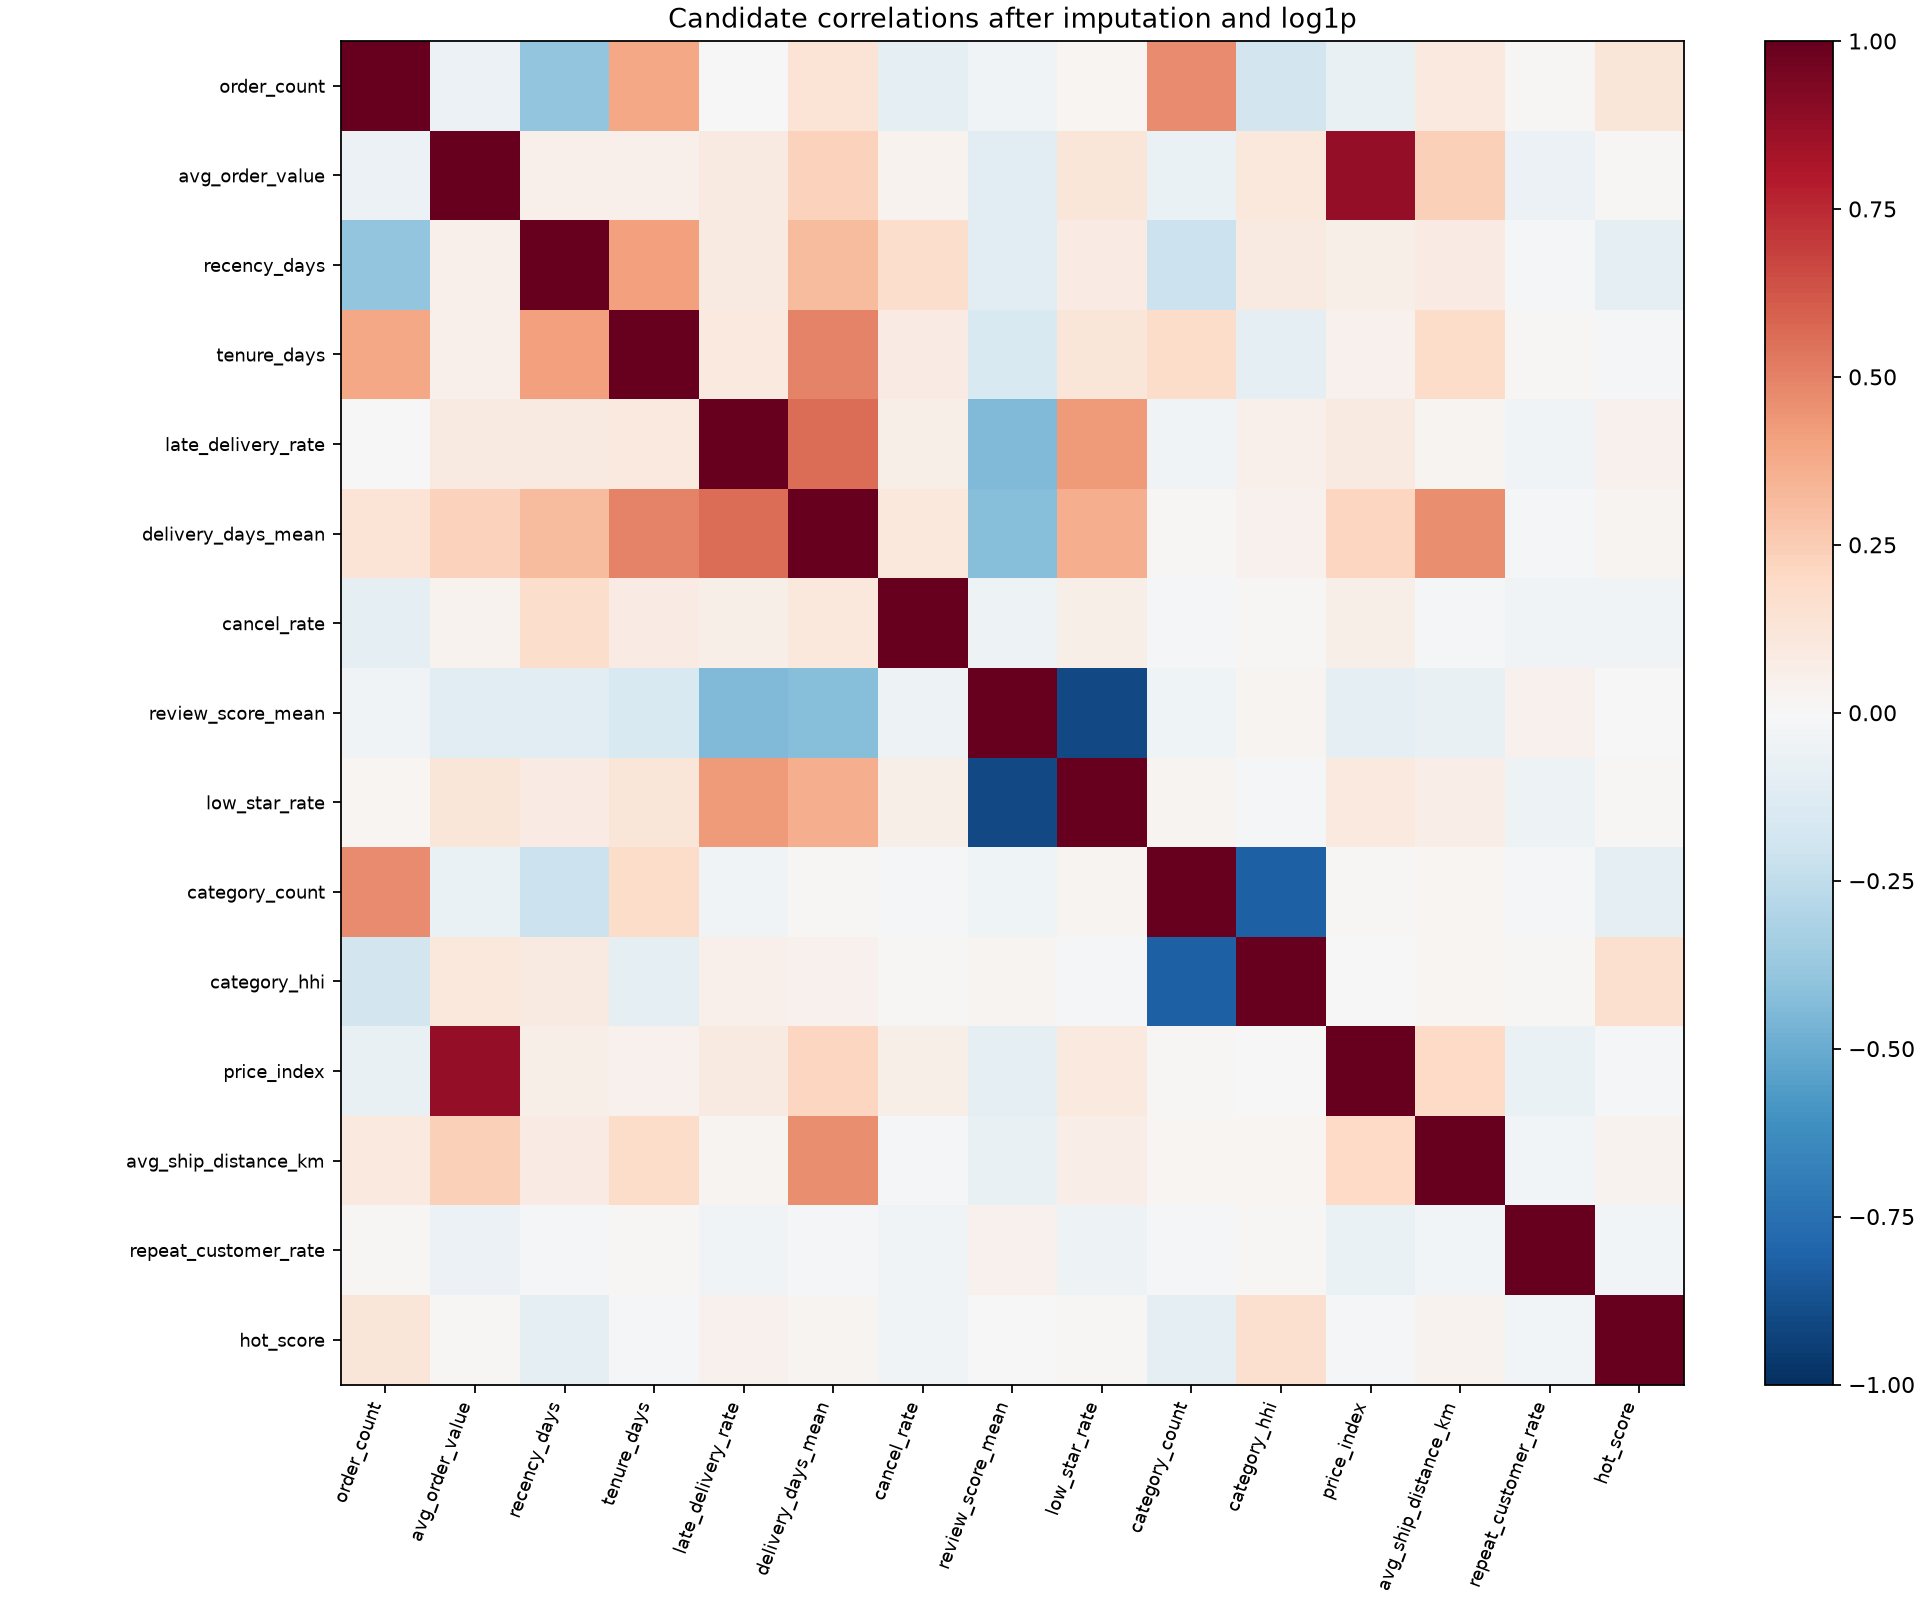

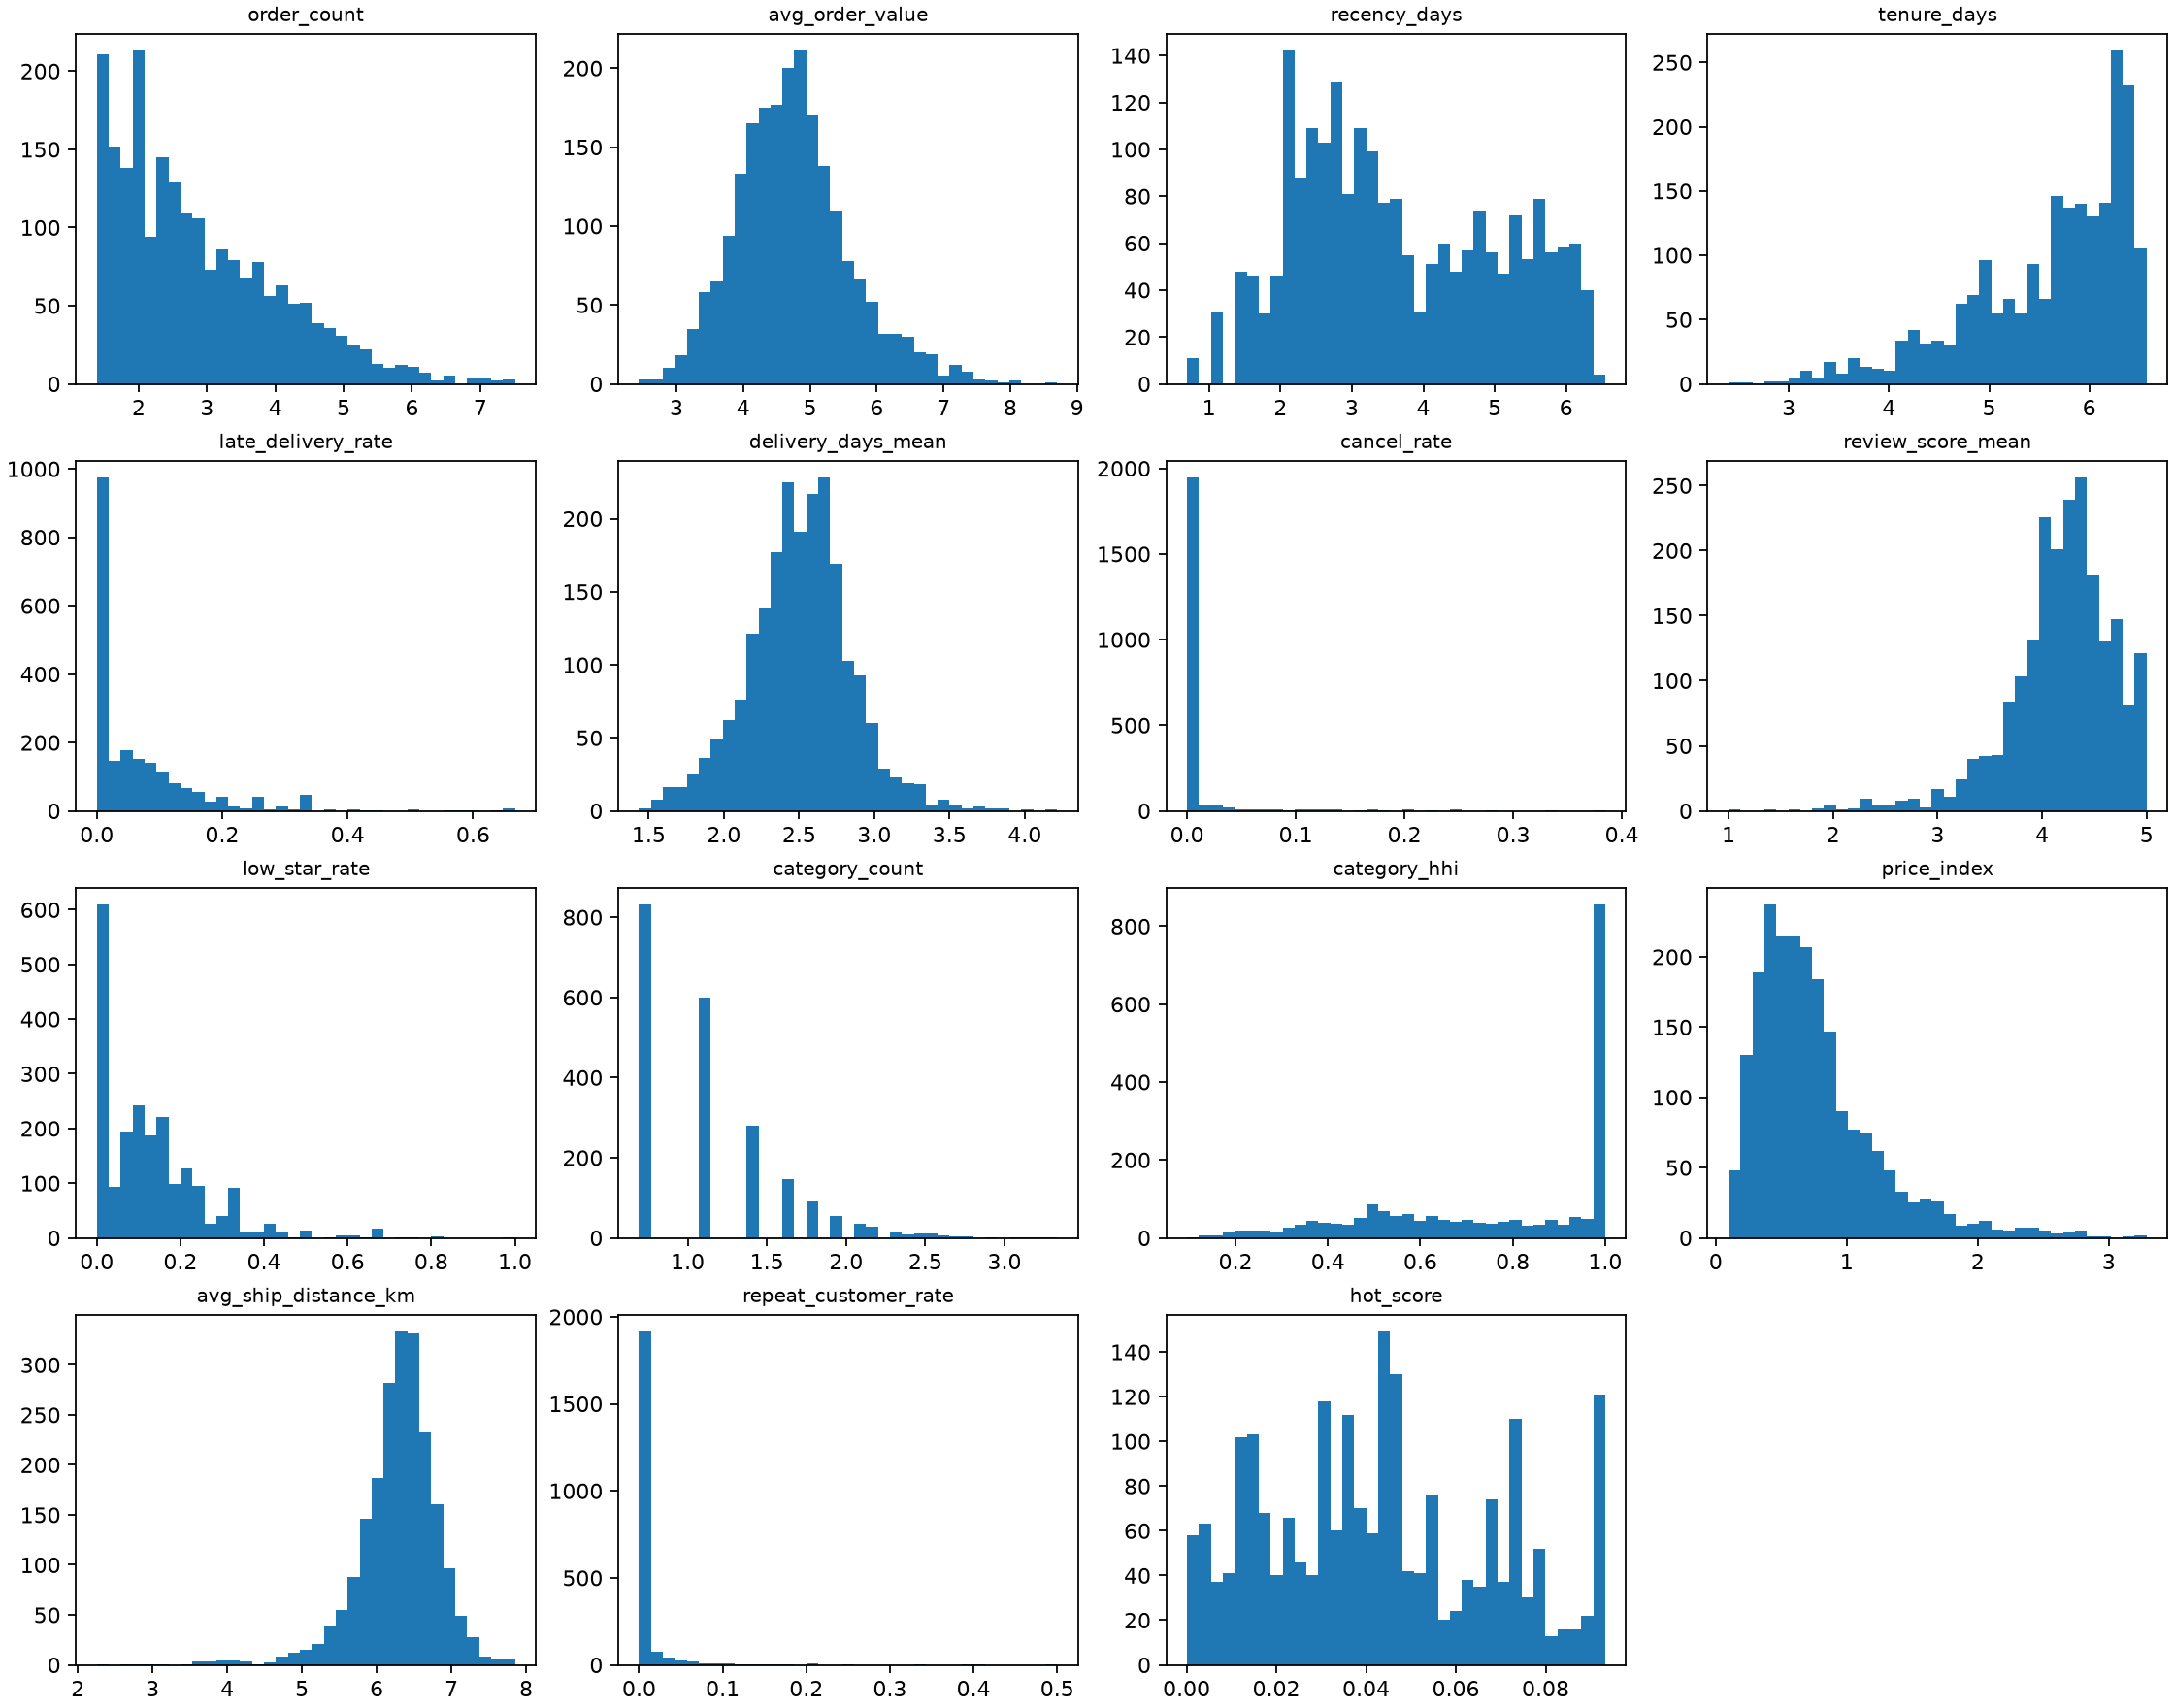

In [5]:
display(pd.DataFrame(metadata['selection_decisions']))
display(pd.read_csv(OUTPUT/'correlation_pairs.csv'))
assert np.isfinite(matrix.to_numpy()).all()
np.testing.assert_allclose(matrix.mean(),0,atol=1e-10)
np.testing.assert_allclose(matrix.std(ddof=0),1,atol=1e-10)
cohort=profiles.loc[profiles.model_eligible].set_index('seller_id')
restored=cohort[metadata['feature_order']].fillna(metadata['medians']).astype(float)
restored[metadata['log1p_features']]=np.log1p(restored[metadata['log1p_features']])
restored=(restored-pd.Series(metadata['mean']))/pd.Series(metadata['scale'])
np.testing.assert_allclose(restored,matrix)
print('PASS: finite, zero mean, unit std, reproducible preprocessing:',matrix.shape)
from IPython.display import display,Image
display(Image(filename=str(OUTPUT/'candidate_correlations.png')))
display(Image(filename=str(OUTPUT/'feature_distributions.png')))


## Bàn giao
Dùng `seller_model_input.csv` và cùng thứ tự seller cho ba thuật toán. `seller_features.csv` chưa chuẩn hóa dùng diễn giải.
Các file JSON lưu hash nguồn, quyết định chọn cột, median/mean/scale và số liệu kiểm tra. `seller_model_input_all.csv` dùng kiểm tra độ nhạy với seller ít đơn.
`review_answer_hours` mô tả thời gian hoàn thành phản hồi khảo sát, không được dùng làm KPI phản hồi của seller.
